In [5]:
!pip install -q easyocr deepface gTTS opencv-python-headless tf-keras

In [6]:
import cv2, re, os, numpy as np, matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from google.colab import files
from IPython.display import display, Audio

# PART A – Medicine Label Reading Assistant




Upload a medicine-bottle/strip photo (or press Cancel to use the synthetic sample).


Saving paracetamol.webp to paracetamol.webp


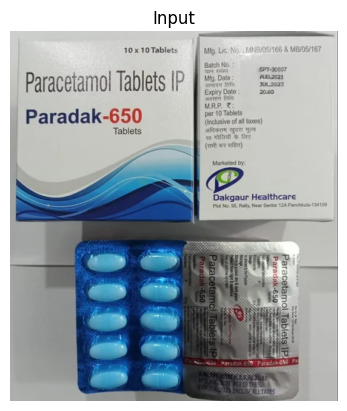

In [7]:
def make_sample_label(path="sample_label.png"):
    img = Image.new("RGB", (700, 460), "white"); d = ImageDraw.Draw(img)
    def font(sz):
        for f in ["/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf"]:
            if os.path.exists(f): return ImageFont.truetype(f, sz)
        return ImageFont.load_default()
    d.rectangle([10, 10, 690, 450], outline="black", width=4)
    d.rectangle([10, 10, 690, 90], fill=(30, 90, 170))
    d.text((30, 25), "PARACETAMOL Tablets IP", fill="white", font=font(36))
    lines = ["Each tablet contains: Paracetamol 500 mg", "Dosage: Take 1 tablet every 6 hours after food",
             "Do not exceed 4 tablets in 24 hours", "Batch No: BX2045A", "Mfg: 03/2025    Exp: 02/2028",
             "Warning: Keep out of reach of children", "Store below 25 C in a dry place"]
    for i, t in enumerate(lines): d.text((30, 110 + i * 46), t, fill="black", font=font(24))
    img.save(path); return path

print("Upload a medicine-bottle/strip photo (or press Cancel to use the synthetic sample).")
try:
    up = files.upload(); img_path = list(up.keys())[0]
except Exception:
    img_path = None
if not img_path: img_path = make_sample_label()
image = cv2.imread(img_path); plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.title("Input"); plt.show()

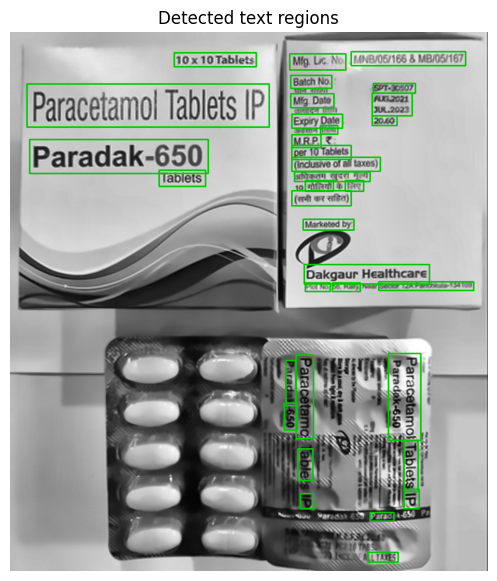

J0x 10 Tablets
Kllg Lc No
BalchKo
Paracetamol Tablets IP
Mlg Date
Expty Date
20L0
MRP
Paradak-650
per 10 Tabels
(Incusue dal taxes)
Tablets
Dakgaur Healthcare
8
1
3
1
6


In [8]:
def preprocess_image(bgr):
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    g = cv2.resize(g, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)      # upscale small text
    g = cv2.fastNlMeansDenoising(g, None, 10)                               # denoise
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)     # contrast

import easyocr
reader = easyocr.Reader(["en"], gpu=True)
proc = preprocess_image(image)
ocr = reader.readtext(proc)                       # [(bbox, text, confidence), ...]
vis = cv2.cvtColor(proc, cv2.COLOR_GRAY2BGR)
for box, txt, conf in ocr:
    pts = np.array(box, dtype=np.int32); cv2.polylines(vis, [pts], True, (0, 200, 0), 2)
plt.figure(figsize=(10, 7)); plt.imshow(vis[..., ::-1]); plt.axis("off"); plt.title("Detected text regions"); plt.show()
raw_text = "\n".join(t for _, t, c in ocr if c > 0.25)
print(raw_text)

In [9]:
def extract_label_info(text):
    t = text.replace("\n", " \n ")
    fix = lambda s: s.replace("O", "0") if re.search(r"\d", s) else s
    info = {}
    m = re.search(r"([A-Z][A-Za-z\-]{3,}(?:\s+[A-Z][a-z]+)?)\s+(?:tablets?|capsules?|syrup|injection|ointment|suspension|drops)", text, re.I)
    info["Medicine name"] = m.group(1).strip() if m else (text.split("\n")[0] if text else "Not found")
    info["Strength"] = ", ".join(re.findall(r"\d+(?:\.\d+)?\s?(?:mg|mcg|µg|g|ml|iu)\b", text, re.I)) or "Not found"
    m = re.search(r"(?:dosage|dose|directions?|take)[:\s].*", text, re.I); info["Dosage / directions"] = m.group(0).strip() if m else "Not found"
    m = re.search(r"(?:exp(?:iry)?(?:\.| date)?|use before)[:\s\-]*([0-9]{1,2}[/\-\.][0-9]{2,4}|[A-Za-z]{3,9}[ \-][0-9]{2,4})", text, re.I); info["Expiry date"] = m.group(1) if m else "Not found"
    m = re.search(r"(?:mfg|mfd|manufactured)[^\d]*([0-9]{1,2}[/\-\.][0-9]{2,4})", text, re.I); info["Manufacturing date"] = m.group(1) if m else "Not found"
    m = re.search(r"(?:batch\s*(?:no\.?)?|b\.?\s?no\.?|lot)[^A-Za-z0-9]*([A-Z0-9\-]{4,})", text, re.I); info["Batch no."] = m.group(1) if m else "Not found"
    w = [l.strip() for l in text.split("\n") if re.search(r"warning|caution|do not|keep out|store|avoid", l, re.I)]; info["Warnings / storage"] = " | ".join(w) or "Not found"
    return info

def is_expired(exp):
    m = re.match(r"(\d{1,2})[/\-\.](\d{2,4})", exp or "")
    if not m: return None
    mon, yr = int(m.group(1)), int(m.group(2)); yr += 2000 if yr < 100 else 0
    import datetime; today = datetime.date.today()
    return (yr, mon) < (today.year, today.month)

info = extract_label_info(raw_text)
for k, v in info.items(): print(f"{k:22s}: {v}")
exp = is_expired(info["Expiry date"])
alert = "⚠️ This medicine appears to be EXPIRED – do not use." if exp else ("✅ Not expired." if exp is False else "Could not verify expiry.")
print("\n" + alert)

Medicine name         : BalchKo
Paracetamol
Strength              : Not found
Dosage / directions   : Not found
Expiry date           : Not found
Manufacturing date    : Not found
Batch no.             : Not found
Warnings / storage    : Not found

Could not verify expiry.


In [10]:
from gtts import gTTS
speech = (f"This medicine is {info['Medicine name']}. Strength: {info['Strength']}. "
          f"{info['Dosage / directions']}. Expiry date: {info['Expiry date']}. {alert.replace('⚠️','').replace('✅','')}")
gTTS(speech).save("label.mp3"); display(Audio("label.mp3"))

def label_qa(question):
    q = question.lower()
    for keys, field in [(["name", "what medicine", "which medicine"], "Medicine name"), (["strength", "mg", "how strong"], "Strength"),
                        (["dose", "dosage", "how to take", "how many", "when"], "Dosage / directions"), (["expire", "expiry", "valid"], "Expiry date"),
                        (["batch", "lot"], "Batch no."), (["warning", "store", "storage", "children", "safe"], "Warnings / storage"), (["manufactur", "made"], "Manufacturing date")]:
        if any(k in q for k in keys): return f"{field}: {info[field]}"
    return "I can answer about name, strength, dosage, expiry, batch, manufacturing date and warnings."
for q in ["What medicine is this?", "How do I take it?", "When does it expire?", "Any warnings?"]: print("Q:", q, "->", label_qa(q))
print("\nℹ️ Always confirm with a pharmacist/doctor – OCR can make mistakes.")

Q: What medicine is this? -> Medicine name: BalchKo
Paracetamol
Q: How do I take it? -> I can answer about name, strength, dosage, expiry, batch, manufacturing date and warnings.
Q: When does it expire? -> Dosage / directions: Not found
Q: Any warnings? -> Warnings / storage: Not found

ℹ️ Always confirm with a pharmacist/doctor – OCR can make mistakes.


# PART B – Emotion-aware Cognitive Assistant (Facial Expression Detection)


In [11]:
from IPython.display import Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename="photo.jpg", quality=0.9):
    js = Javascript('''
      async function takePhoto(quality) {
        const div = document.createElement('div'); const btn = document.createElement('button'); btn.textContent = '📸 Capture';
        div.appendChild(btn); const video = document.createElement('video'); video.style.display = 'block';
        const stream = await navigator.mediaDevices.getUserMedia({video: true}); document.body.appendChild(div); div.appendChild(video);
        video.srcObject = stream; await video.play(); google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
        await new Promise((resolve) => btn.onclick = resolve);
        const canvas = document.createElement('canvas'); canvas.width = video.videoWidth; canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0); stream.getVideoTracks()[0].stop(); div.remove();
        return canvas.toDataURL('image/jpeg', quality);
      }''')
    display(js); data = eval_js("takePhoto({})".format(quality))
    open(filename, "wb").write(b64decode(data.split(",")[1])); return filename

26-11-20 16:12:46 - Directory /root/.deepface has been created
26-11-20 16:12:46 - Directory /root/.deepface/weights has been created
Choose: 1 = webcam capture, 2 = upload a face image
Enter 1 or 2: 2


Saving images.jfif to images.jfif
26-11-20 16:13:14 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 93.2MB/s]


Face 1: happy  (100.0%)
🤖 Assistant: You look happy! 😊 Great to see that. Want to keep the momentum going with something fun or productive?


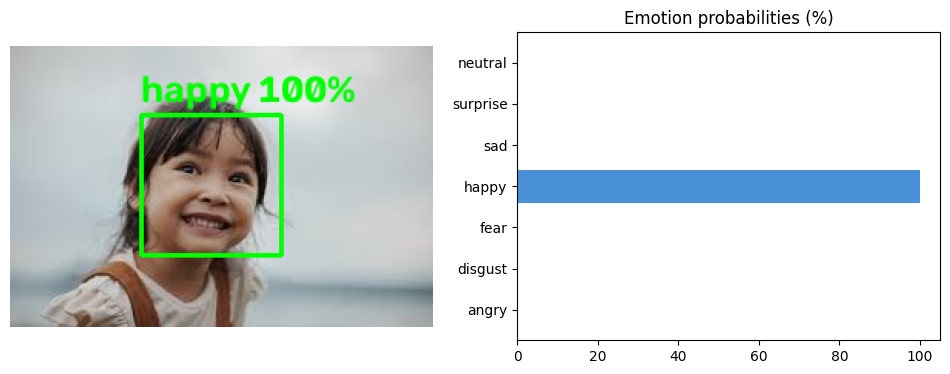

In [12]:
from deepface import DeepFace

responses = {
 "happy":    "You look happy! 😊 Great to see that. Want to keep the momentum going with something fun or productive?",
 "sad":      "You seem a little down. 💙 I'm here to listen. Would you like a calming tip, a short break, or to talk about it?",
 "angry":    "I sense some frustration. Let's take a slow deep breath together – in for 4, hold 4, out for 6. I'll keep things short and simple.",
 "fear":     "You seem anxious or worried. You're safe here. Let's go step by step – what's on your mind?",
 "surprise": "You look surprised! 😮 Is there something I can explain or help you with?",
 "disgust":  "Something seems off or unpleasant. Would you like to change the topic or tell me what's bothering you?",
 "neutral":  "You look calm and focused. How can I help you today?",
}
def analyze_emotion(img_path):
    res = DeepFace.analyze(img_path, actions=["emotion"], enforce_detection=False)
    return res if isinstance(res, list) else [res]

def emotion_assistant(img_path):
    img = cv2.imread(img_path); faces = analyze_emotion(img_path)
    for i, f in enumerate(faces):
        r = f["region"]; emo = f["dominant_emotion"]; scores = f["emotion"]
        cv2.rectangle(img, (r["x"], r["y"]), (r["x"] + r["w"], r["y"] + r["h"]), (0, 255, 0), 2)
        cv2.putText(img, f"{emo} {scores[emo]:.0f}%", (r["x"], max(r["y"] - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
        print(f"Face {i+1}: {emo}  ({scores[emo]:.1f}%)"); print("🤖 Assistant:", responses[emo])
    fig, ax = plt.subplots(1, 2, figsize=(12, 4)); ax[0].imshow(img[..., ::-1]); ax[0].axis("off")
    ax[1].barh(list(faces[0]["emotion"].keys()), list(faces[0]["emotion"].values()), color="#4a90d9"); ax[1].set_title("Emotion probabilities (%)"); plt.show()
    return faces[0]["dominant_emotion"]

print("Choose: 1 = webcam capture, 2 = upload a face image"); choice = input("Enter 1 or 2: ").strip()
face_path = take_photo() if choice == "1" else list(files.upload().keys())[0]
current_emotion = emotion_assistant(face_path)

### Emotion-aware conversation: the assistant adapts its tone to the detected emotion

In [13]:
tone = {"happy": "enthusiastic", "sad": "gentle and supportive", "angry": "calm and concise", "fear": "reassuring", "surprise": "explanatory", "disgust": "neutral and respectful", "neutral": "friendly"}
def adaptive_reply(user_text, emotion):
    base = f"[Tone: {tone[emotion]}] "
    t = user_text.lower()
    if re.search(r"help|stuck|problem|error", t): return base + {"angry": "Sorry for the trouble. Tell me the one thing that's failing and I'll fix it first.", "sad": "That sounds tough, but we can sort it out together, step by step."}.get(emotion, "Sure, tell me more and I'll help.")
    if re.search(r"tired|stress|exam|worried", t): return base + "Take a short break, drink some water, and let's plan the work in small parts. You've got this."
    return base + responses[emotion]
for msg in ["I'm stuck with this lab and getting errors", "I'm stressed about exams", "Hello"]:
    print("User:", msg); print("Assistant:", adaptive_reply(msg, current_emotion), "\n")

User: I'm stuck with this lab and getting errors
Assistant: [Tone: enthusiastic] Sure, tell me more and I'll help. 

User: I'm stressed about exams
Assistant: [Tone: enthusiastic] Take a short break, drink some water, and let's plan the work in small parts. You've got this. 

User: Hello
Assistant: [Tone: enthusiastic] You look happy! 😊 Great to see that. Want to keep the momentum going with something fun or productive? 

